In [79]:
import pandas as pd
import seaborn as sns
import numpy as np

In [80]:
df=pd.read_csv('Housing.csv')
df.describe()
df


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [81]:
df.isnull().sum()                                                      #missing values

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [82]:
from sklearn.preprocessing import OrdinalEncoder                                        #ordinal encoding

oe =OrdinalEncoder(categories=[['furnished' ,'semi-furnished','unfurnished']])
df[['furnishingstatus']]= oe.fit_transform(df[['furnishingstatus']])
print(df['furnishingstatus'])


from sklearn.preprocessing import LabelEncoder                                                #label encoding
le = LabelEncoder()                                                     
df['mainroad'] = le.fit_transform(df['mainroad'])
df['mainroad']





0      0.0
1      0.0
2      1.0
3      0.0
4      0.0
      ... 
540    2.0
541    1.0
542    2.0
543    0.0
544    2.0
Name: furnishingstatus, Length: 545, dtype: float64


0      1
1      1
2      1
3      1
4      1
      ..
540    1
541    0
542    1
543    0
544    1
Name: mainroad, Length: 545, dtype: int64

In [83]:
df['guestroom'] = le.fit_transform(df['guestroom'])
df['guestroom']

0      0
1      0
2      0
3      0
4      1
      ..
540    0
541    0
542    0
543    0
544    0
Name: guestroom, Length: 545, dtype: int64

In [84]:
df['basement'] = le.fit_transform(df['basement'])
df['basement']

0      0
1      0
2      1
3      1
4      1
      ..
540    1
541    0
542    0
543    0
544    0
Name: basement, Length: 545, dtype: int64

In [85]:
df['hotwaterheating'] = le.fit_transform(df['hotwaterheating'])
df['hotwaterheating']

0      0
1      0
2      0
3      0
4      0
      ..
540    0
541    0
542    0
543    0
544    0
Name: hotwaterheating, Length: 545, dtype: int64

In [86]:
df['airconditioning'] = le.fit_transform(df['airconditioning'])
df['airconditioning']

0      1
1      1
2      0
3      1
4      1
      ..
540    0
541    0
542    0
543    0
544    0
Name: airconditioning, Length: 545, dtype: int64

In [87]:
df['prefarea'] = le.fit_transform(df['prefarea'])
df['prefarea']

0      1
1      0
2      1
3      1
4      0
      ..
540    0
541    0
542    0
543    0
544    0
Name: prefarea, Length: 545, dtype: int64

In [88]:
df['price']                                                             #outlier detection
q1=df['price'].quantile(0.25)
q3=df['price'].quantile(0.75)

outliers = df[(df['price']>q1)|(df['price']<q3)]
print(outliers)



df['salary'] = np.clip(df['price'], q1,q3)                                   #outlier handling - clipping



        price  area  bedrooms  bathrooms  stories  mainroad  guestroom  \
0    13300000  7420         4          2        3         1          0   
1    12250000  8960         4          4        4         1          0   
2    12250000  9960         3          2        2         1          0   
3    12215000  7500         4          2        2         1          0   
4    11410000  7420         4          1        2         1          1   
..        ...   ...       ...        ...      ...       ...        ...   
540   1820000  3000         2          1        1         1          0   
541   1767150  2400         3          1        1         0          0   
542   1750000  3620         2          1        1         1          0   
543   1750000  2910         3          1        1         0          0   
544   1750000  3850         3          1        2         1          0   

     basement  hotwaterheating  airconditioning  parking  prefarea  \
0           0                0           

<Axes: >

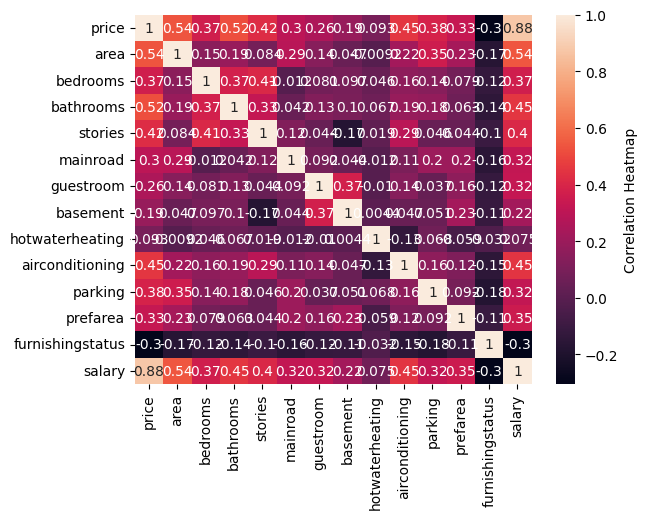

In [89]:
correlation=df.corr(numeric_only=True)

sns.heatmap(                                                       #Correlation Heatmap
    correlation,
    annot=True,
    cbar_kws={"label":"Correlation Heatmap"}

    )

In [90]:
y=df['price']                                                         #output column

In [91]:
x=df.drop(columns=['price'],axis=1)                                               #input columns

In [92]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2)                                       #splitting training and testing dataset

In [93]:
x_train

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,salary
139,6360,3,1,1,1,1,1,0,1,2,1,0.0,5740000
83,6000,3,2,4,1,0,0,0,1,0,0,1.0,5740000
207,3000,3,1,2,1,0,1,0,1,0,0,1.0,4900000
32,4880,4,2,2,1,0,0,0,1,1,1,0.0,5740000
148,6360,3,1,3,1,0,0,0,0,0,1,1.0,5600000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,6420,3,2,3,1,0,0,0,1,0,1,0.0,5740000
317,4992,3,2,2,1,0,0,0,0,2,0,2.0,4060000
77,6500,3,2,3,1,0,0,0,1,0,1,0.0,5740000
63,6360,4,2,3,1,0,0,0,1,2,1,0.0,5740000


In [94]:
x_test

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,salary
293,4410,2,1,1,0,0,0,0,0,1,0,2.0,4200000
458,3850,3,1,2,1,0,0,0,0,0,0,2.0,3430000
408,4000,2,1,1,1,0,0,0,0,0,0,2.0,3430000
183,7980,3,1,1,1,0,0,0,0,1,1,1.0,5145000
348,3150,2,2,1,0,0,1,0,0,0,0,1.0,3815000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
266,4880,3,1,1,1,0,0,0,0,2,1,2.0,4403000
366,3630,2,1,1,1,0,1,0,0,0,0,0.0,3675000
384,4500,2,1,1,0,0,0,0,0,0,0,0.0,3570000
220,8100,4,1,4,1,0,1,0,1,2,0,1.0,4795000


In [95]:
y_train

139    5740000
83     6580000
207    4900000
32     8295000
148    5600000
        ...   
76     6650000
317    4060000
77     6650000
63     7035000
215    4830000
Name: price, Length: 436, dtype: int64

In [96]:
y_test

293    4200000
458    3115000
408    3430000
183    5145000
348    3815000
        ...   
266    4403000
366    3675000
384    3570000
220    4795000
136    5740000
Name: price, Length: 109, dtype: int64

In [97]:
from sklearn.linear_model import LinearRegression
le = LinearRegression()

model=le.fit(x_train,y_train)                                           #training model

In [98]:
model

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[87.73,-0. ,-0. ,..., 0. , 0. , 1.65]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['area','bedrooms','bathrooms',...,'prefarea','furnishingstatus','salary']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3.093e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [99]:
y_predict = model.predict(x_test)                                  #testing model
y_test

293    4200000
458    3115000
408    3430000
183    5145000
348    3815000
        ...   
266    4403000
366    3675000
384    3570000
220    4795000
136    5740000
Name: price, Length: 109, dtype: int64

In [100]:
y_predict                                                     #model prediction

array([4211679.71786674, 2894316.57744646, 2907476.81493915,
       6081359.21635634, 3467017.98328174, 2856590.58271041,
       7013979.52108811, 6715681.02037575, 7013979.5285586 ,
       6782359.50854728, 6444890.50650381, 4266952.65871801,
       3069786.29697325, 4450163.40331773, 2835534.23266225,
       5767784.64479345, 6373464.17454142, 2976348.67331812,
       6813066.70760442, 2746044.66562735, 3136903.45541959,
       4322586.73884519, 3165623.29807071, 4122097.32951465,
       2830270.13011505, 6884131.94102566, 4182639.45745603,
       6977130.90970459, 6799906.47626187, 4537052.20373071,
       3974692.58153668, 3869979.10339812, 3021532.12478334,
       6339123.7300295 , 6756039.0345356 , 4228349.3316161 ,
       2832902.17594874, 6966602.70640579, 5617892.30999383,
       2874137.56949376, 6940282.23918359, 2823251.35076827,
       5315599.43395521, 2840798.33302362, 6843773.90824237,
       2835972.92501741, 4652417.70275031, 7095748.42351532,
       4557302.93984011,